# **<u>Machine Learning Model</u>**

A Random Forest multi-class classification model is selected to identify patterns in ACE National Lottery Project Grants and assess whether award funding tiers can be predicted from the available features.

The objective is to evaluate the model’s predictive performance and feature importance to understand its potential analytical value. Findings may reveal patterns in recorded awards but do not establish causation or justify automated funding decisions.

### **Target Variable**

The continuous <code>award_amount</code> variable is converted into a categorical target, <code>award_tier</code>, using the 33rd percentile (£23,750) and 67th percentile (£30,000) as boundaries. This produces three approximately balanced classes: Low (33.02%), Medium (34.41%) and High (32.58%).

### **Features**

The model uses <code>ace_area</code>, <code>local_authority</code> and <code>main_discipline</code> as input features to predict <code>award_tier</code>, exploring geographical and disciplinary patterns in award amounts. The <code>strand</code> variable was excluded because its categorical definitions contain award-value thresholds, creating a risk of target leakage.

### **Model Evaluation**

Stratified five-fold cross-validation is applied to the training data to assess model consistency by comparing performance metrics across five folds. The mean and standard deviation of the cross-validation scores indicate the model's average performance and how much it varies across different data splits, while stratification preserves the approximate distribution of funding tiers in each fold. 

The selected model is then evaluated on the unseen test set using accuracy, macro F1-score, a confusion matrix, precision and recall. Feature importance is analysed separately to identify which variables contribute most to the model's predictions.


</b>

## **<u>Load Libraries and Data</u>**

Import the required libraries for data manipulation, model training, cross-validation, evaluation and visualisation. Load the prepared modelling dataset from the CSV file into a pandas DataFrame and display the first few rows to inspect its structure and confirm that the data has loaded correctly.

In [1]:
# Data manipulation
import pandas as pd
import numpy as np

# Data splitting and model evaluation
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
)
from sklearn.metrics import (
   accuracy_score,
   classification_report,
   confusion_matrix,
   precision_score,
   recall_score,
   f1_score
)

# Machine learning model
from sklearn.ensemble import RandomForestClassifier

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
data = pd.read_csv('/Users/admin/Documents/Code Institute/ace_project/data/ml_model/model_data.csv')

# Display the first few rows of the dataset
data.head()

,ace_area,local_authority,main_discipline,award_tier
0,South West,"Bournemouth, Christchurch and Poole",Music,Medium
1,South West,Portsmouth,Theatre,Medium
2,South West,Bath and North East Somerset,Combined arts,Medium
3,South West,"Bristol, City of",Visual arts,High
4,South West,South Gloucestershire,Theatre,Low


</b>

## **<u>Model Preperation</u>**

### **Predictors and Target**

In [2]:
# Separate features and target variable
x = data.drop('award_tier', axis=1)  # Features
y = data['award_tier']  # Target variable

# Check the shape of the features and target variable
print(f"Features shape: {x.shape}")
print(f"Target variable shape: {y.shape}")

Features shape: (5452, 3)
Target variable shape: (5452,)


</b>

### **Split Train/Test Data**

The dataset is divided into training (80%) and test (20%) sets. The training set is used for model development and stratified five-fold cross-validation, while the unseen test set is reserved for the final evaluation of predictive performance.

The <code>stratify=y</code> parameter preserves the approximate distribution of the three <code>award_tier</code> classes across both sets. Setting <code>random_state=42</code> ensures the split is reproducible. The value has no statistical significance; it was selected as a fixed seed, with a small nod to The Hitchhiker's Guide to the Galaxy.

In [3]:
# Split the dataset into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    x,                  # Predictor features
    y,                  # Target variable: award_tier
    test_size=0.2,      # Reserve 20% for final evaluation
    random_state=42,    # Ensure reproducibility
    stratify=y          # Preserve the distribution of funding tiers
)

# Validate the dimensions of the resulting datasets.
print("Training features:", X_train.shape)
print("Test features:", X_test.shape)
print("Training target:", y_train.shape)
print("Test target:", y_test.shape)

Training features: (4361, 3)
Test features: (1091, 3)
Training target: (4361,)
Test target: (1091,)


</b>

## **<u>Preprocess Categorical Features</u>**

One-hot encoding is used to convert the categorical predictor variables <code>ace_area</code>, <code>local_authority</code> and <code>main_discipline</code> into numerical features suitable for the Random Forest classifier. 

A <code>ColumnTransformer</code> applies <code>OneHotEncoder</code> to these columns, generating binary indicator features for each category. Setting <code>handle_unknown="ignore"</code> allows the model to process categories encountered during testing that were not present during training, without raising an error.

In [4]:
# Import tools for preprocessing categorical columns and building a scikit-learn pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# List the categorical predictor variables that require one-hot encoding
categorical_cols = [
   "ace_area",
   "local_authority",
   "main_discipline"
]

# Create a preprocessing transformer for the categorical variables
preprocessor = ColumnTransformer(
   transformers=[
       (
           "categorical",
           OneHotEncoder(
               handle_unknown="ignore"
           ),
           categorical_cols
       )
   ]
)

# Fit the encoder on training data and transform the features
X_train_encoded = preprocessor.fit_transform(X_train)

# Check the transformed data dimensions
print("Original shape:", X_train.shape)
print("Encoded shape:", X_train_encoded.shape)

Original shape: (4361, 3)
Encoded shape: (4361, 309)


</b>

### **Stratified Cross-Validation Folds**

Stratified five-fold cross-validation is used during model development to assess the consistency of the Random Forest model. The training data is partitioned into five folds, maintaining approximately the same proportion of Low, Medium and High funding tiers in each fold. The model is trained on four folds and validated on the remaining fold, repeating the process five times so that each fold is used once for validation.

Shuffling randomises the order of the data before partitioning, while <code>random_state=42</code> ensures reproducibility. Cross-validation is applied exclusively to the training set, keeping the unseen test set separate for final model evaluation.

In [5]:
# Set up cross-validation for model evaluation
from sklearn.model_selection import StratifiedKFold

# Create a stratified 5-fold cross-validation splitter
cv = StratifiedKFold(
   n_splits=5,      # Use 5 folds for cross-validation
   shuffle=True,    # Shuffle rows before splitting to reduce ordering bias
   random_state=42  # Fix random state for reproducibility
)

# Check the number of folds and the total number of training records
print("Number of folds:", cv.get_n_splits(X_train, y_train))
print("Total training records:", len(y_train))

Number of folds: 5
Total training records: 4361


</b>

## <u>**Random Forest Model Training**</u>

Train the Random Forest classifier on the training set. The preprocessing pipeline applies one-hot encoding to the categorical predictor variables before fitting the model, allowing it to learn patterns associated with the three funding tiers.

The unseen test set remains separate from model training and is reserved for the final evaluation of predictive performance.

In [6]:
# Create the complete modelling pipeline
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        random_state=42
    ))
])

# Train the final pipeline on all training records
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['ace_area','local_authority','main_discipline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaini

</b>

## <u>**Model Evaluation**</u>

Evaluate the trained model on the unseen test set using accuracy, precision, recall, F1-score and a confusion matrix. Each metric provides a different perspective on predictive performance:

- **Accuracy** measures the proportion of all predictions that correctly match the actual funding tiers.

- **Precision** measures how many predictions for each funding tier are correct, indicating how often the model assigns a tier accurately when it predicts that class.

- **Recall** measures how many actual cases in each funding tier the model correctly identifies.

- **F1-score** combines precision and recall using their harmonic mean, balancing the two measures.

- **Confusion matrix** compares actual and predicted funding tiers, showing correct classifications and misclassifications across the Low, Medium and High classes.

Together, these metrics assess overall performance and reveal how effectively the model distinguishes between funding tiers. The macro F1-score gives equal weight to each class, making it useful for comparing performance across the three tiers.

</b>

### **Cross-Validation Result**

Assess model consistency across the five folds using the mean macro F1-score and its standard deviation. The mean indicates the model's average classification performance across the folds, while the standard deviation measures how much performance varies between them. A higher mean and lower standard deviation suggest stronger and more consistent performance across different training and validation splits.

In [7]:
# Evaluate macro F1-score across five folds
cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro"
)

# Display cross-validation results
print("Fold macro F1-scores:", cv_scores)
print("Mean macro F1-score:", cv_scores.mean())
print("Standard deviation:", cv_scores.std())

Fold macro F1-scores: [0.39092089 0.38419643 0.38972563 0.40128693 0.40168891]
Mean macro F1-score: 0.39356375528895443
Standard deviation: 0.006857527218052508


The Random Forest achieves a mean macro F1-score of 0.394 across five stratified validation folds, with a standard deviation of 0.007.

The macro F1-score ranges from 0 to 1, with higher scores indicating a better balance between precision and recall. A score of 0.394 indicates limited predictive performance across the three funding tiers, as the model struggles to balance correctly identifying each tier with making accurate predictions for it. Macro averaging gives equal weight to the Low, Medium and High classes, regardless of their number of observations.

The low standard deviation indicates that performance varies little across the five folds. However, consistent performance does not necessarily indicate strong predictive ability. 

</b>

### **Train Final Model**

Fit the Random Forest classifier on the full training set using the selected features and preprocessing pipeline. This allows the model to learn patterns from all available training data before its predictive performance is evaluated on the unseen test set using accuracy, precision, recall, F1-score and a confusion matrix.

In [8]:
# Fit the pipeline on the complete training dataset
rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['ace_area','local_authority','main_discipline']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaini

</b>

### **Generate Test-Set Prediction**

The final Random Forest model is trained on the entire training set after cross-validation. Generate predictions for the unseen test set and evaluate them using accuracy, precision, recall, F1-score and a confusion matrix. These results provide an independent assessment of the model's predictive performance on data that was not used during training.

In [9]:
# Predict funding tiers for the unseen test data
y_pred = rf_pipeline.predict(X_test)

# Display the results in dataframe format for better readability
results_df = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_pred
})

# Display the first 10 predictions alongside actual values
results_df.head(10) 

,Actual,Predicted
1896,Low,Low
1272,Low,Low
3510,High,Medium
840,Low,Low
3064,Medium,Medium
745,High,Medium
2927,Low,Low
1984,Low,Low
310,Medium,Medium
4903,Medium,High


In [10]:
# Give each prediction a unique ID
results_df = results_df.reset_index(drop=True)
results_df["Prediction ID"] = results_df.index + 1

# Save for Tableau
results_df.to_csv("random_forest_predictions.csv", index=False)

# Display model predictions
display(results_df.head())

,Actual,Predicted,Prediction ID
0,Low,Low,1
1,Low,Low,2
2,High,Medium,3
3,Low,Low,4
4,Medium,Medium,5


</b>

### **Accuracy**

Accuracy measures the proportion of test records for which the model correctly predicts the funding tier.

In [11]:
# Calculate the proportion of correctly classified test samples
accuracy = accuracy_score(y_test, y_pred)

# Print the model's accuracy on the unseen test set
print("Test accuracy:", accuracy)

Test accuracy: 0.39596700274977087


The Random Forest achieves a test accuracy of 39.60%, meaning that approximately 40% of unseen records were assigned to the correct funding tier. This result is consistent with the cross-validation findings, suggesting that the model's predictive performance remains limited on unseen data.

</b>

### **Precision**

Macro precision measures how often the model's predictions are correct for each funding tier, calculating precision separately for Low, Medium and High before averaging the results with equal weight for each tier.

In [12]:
# Compute macro precision on the test set:
macro_precision = precision_score(
    y_test,          # Actual award_tier values in the test set
    y_pred,          # Predicted award_tier values from the model
    average="macro", # Average precision equally across all tiers
    zero_division=0  # Prevent divide-by-zero warnings for absent classes
)

# Display the macro precision score for the model
print("Macro precision:", macro_precision)

Macro precision: 0.39598076724100456


The macro precision score of 39.6% indicates that, on average, approximately 39.6% of predictions for each funding tier are correct, with Low, Medium and High tiers weighted equally.

</b>

### **Recall**

Macro recall measures how effectively the model identifies actual cases in each funding tier, averaging recall across the Low, Medium and High classes with equal weight.

In [13]:
# Calculate macro recall on the unseen test set.
macro_recall = recall_score(
    y_test,          # Actual award_tier values in the test set
    y_pred,          # Predicted award_tier values from the model
    average="macro", # Average recall across all target classes
    zero_division=0  # Avoid division-by-zero warnings for classes with no predictions
)

# Display the macro recall score for model evaluation
print("Macro recall:", macro_recall)

Macro recall: 0.39577187316174434


The model achieves a macro recall of 39.58%, indicating limited ability to correctly identify actual records across the Low, Medium and High funding tiers.

</b>

### **F1-Score**

Macro F1-score combines precision and recall for each funding tier using their harmonic mean, then averages the three scores with equal weight for the Low, Medium and High tiers.

In [14]:
# Calculate the macro F1-score for the test set predictions.
macro_f1 = f1_score(
    y_test,           # Actual funding tiers from the unseen test set
    y_pred,           # Predicted funding tiers from the model
    average="macro",  # Compute the unweighted mean across all classes
    zero_division=0   # Prevent division-by-zero warnings for missing classes
)

# Display the macro F1-score to evaluate model performance
print("Macro F1-score:", macro_f1)

Macro F1-score: 0.3956274199687346


The models macro F1-score is 39.56% on the test dataset. Macro F1-score combines precision and recall for each funding tier and averages them equally. The result indicates modest predictive performance across the Low, Medium and High funding tiers.

</b>

### **Confusion Matrix**

The confusion matrix shows the number of records correctly classified and misclassified across the Low, Medium and High funding tiers, highlighting which tiers the model most frequently confuses with one another.

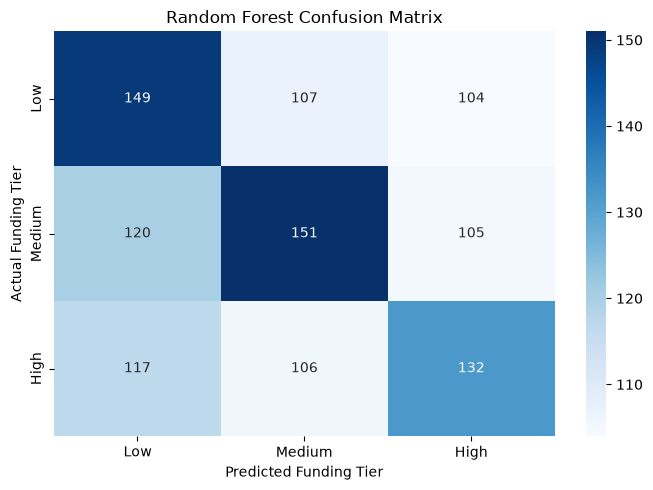

In [15]:
# Define the order of labels for the confusion matrix
labels = ["Low", "Medium", "High"]

# Compute the confusion matrix to evaluate the classification performance
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

# Visualise the confusion matrix
plt.figure(figsize=(7, 5))


# Create a heatmap to display the confusion matrix values
sns.heatmap(
    cm,                    # Confusion matrix array
    annot=True,            # Display the count in each cell
    fmt="d",               # Format values as integers
    cmap="Blues",          # Use a blue colormap for the heatmap
    xticklabels=labels,    # Set x-axis labels to ["Low", "Medium", "High"]
    yticklabels=labels     # Set y-axis labels to ["Low", "Medium", "High"]
)

# Add descriptive labels and title to the confusion matrix plot
plt.title("Random Forest Confusion Matrix")     
plt.xlabel("Predicted Funding Tier")            
plt.ylabel("Actual Funding Tier")               

# Adjust the layout and display the chart
plt.tight_layout()
plt.show()

The confusion matrix shows that the Random Forest correctly classified 149 Low-tier, 151 Medium-tier and 132 High-tier records.

Misclassifications occurred across all three funding tiers, indicating difficulty distinguishing between award categories. These results suggest that the selected categorical features provide limited predictive separation between the funding tiers.

</b>

## <u>**Feature Importance**</u>

Examine feature importance to identify which categorical predictors contribute most to the Random Forest's funding-tier predictions. However, interpret the results with caution given the model's limited predictive performance.

Feature importance indicates how the fitted model uses the available features to make predictions; it does not establish causal relationships or explain the factors underlying actual funding decisions. Interpreting the results requires additional domain knowledge to understand the nuances of main disciplines and regional differences.

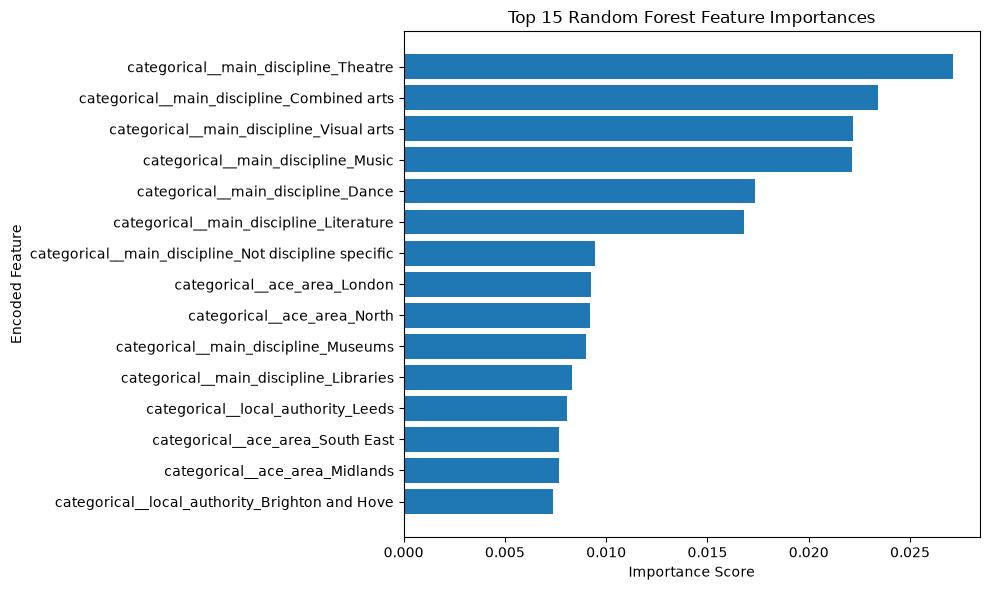

In [16]:
# Create a DataFrame of encoded feature names and their importance scores
importance_df = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": rf_pipeline.named_steps["classifier"].feature_importances_
})

# Select the top 15 most important features and sort for a readable bar chart
top_features = importance_df.nlargest(15, "Importance").sort_values(
    by="Importance",
    ascending=True
)

# Create a larger figure for better readability in the notebook
plt.figure(figsize=(10, 6))

# Plot the top 15 encoded features as a horizontal bar chart
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

# Add labels and title to explain the visualisation
plt.title("Top 15 Random Forest Feature Importances")
plt.xlabel("Importance Score")
plt.ylabel("Encoded Feature")

# Adjust layout to avoid clipping and display the chart
plt.tight_layout()
plt.show()

Main discipline, particularly Theatre and Combined Arts, ranks highly among the encoded features, followed by ACE area. This aligns with the EDA findings, which identified these disciplines as receiving the highest award amounts. However, feature importance reflects how the model uses these features to make predictions; it does not establish causation or explain the reasons behind funding outcomes.

</b>

## <u>**Save Model**</u>

Save the trained Random Forest pipeline as <code>random_forest_award_tier_model.joblib</code> using <code>joblib</code>. This preserves both the fitted preprocessing steps and the classification model, allowing the complete pipeline to be reloaded and reused for future predictions without retraining.

In [17]:
import joblib

# Save the complete trained pipeline
#joblib.dump(rf_pipeline, "random_forest_award_tier_model.joblib")

Reload the saved pipeline using <code>joblib.load()</code> and apply it to new data, ensuring that the input features match the training data in column names and format.

</b>

## <u>**ML Model Conclusion**</u>

Five-fold cross-validation produced a mean macro F1-score of 39.36%, indicating consistent but limited classification performance across the training folds. The Random Forest model achieved a test accuracy of 39.60% and a macro F1-score of 39.56%. The confusion matrix shows frequent misclassifications across the Low, Medium and High award tiers.

Overall, the model demonstrates limited predictive ability using ACE area, local authority and main discipline. Although feature importance identified main discipline and ACE area as influential predictors, these features are insufficient for reliable classification. Arts and culture funding involves nuanced, project-specific considerations that may not be captured by the selected categorical features.

The predictions and feature importance rankings indicate patterns within the dataset but do not establish causation or explain the reasoning behind individual funding decisions.